In [1]:
import glob
import os
import pandas as pd

csv_files = glob.glob("*.csv")
print("Files found in Colab:", csv_files)

gwl_matches = [f for f in csv_files if "gwl" in f.lower()]
gwq_matches = [f for f in csv_files if "gwq" in f.lower()]

if not gwl_matches or not gwq_matches:
    raise FileNotFoundError(
        "Missing file! Upload both CSVs (one with 'gwl' and one with 'gwq' in the filename) using the left Folder panel."
    )

gwl_raw = pd.read_csv(gwl_matches[0])
gwq_raw = pd.read_csv(gwq_matches[0])

print("\n--- Water Level (GWL) ---")
print("Rows and Columns:", gwl_raw.shape)
print("Columns:", list(gwl_raw.columns))

print("\n--- Water Quality (GWQ) ---")
print("Rows and Columns:", gwq_raw.shape)
print("Columns:", list(gwq_raw.columns))

Files found in Colab: ['gwl_manual_quarterly_cgwb_jk_2021_2025.csv', 'gwq_physical_parameter_manual_cgwb_jk_1961_2025.csv']

--- Water Level (GWL) ---
Rows and Columns: (1648, 21)
Columns: ['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'RL_MSL', 'Data Acquisition Time', 'Groundwater Level Quarterly Manual (meter)']

--- Water Quality (GWQ) ---
Rows and Columns: (2355, 21)
Columns: ['SlNo', 'Station', 'Agency', 'State LGD Code', 'State', 'District LGD Code', 'District', 'Tehsil', 'Block', 'Village', 'River', 'Basin', 'Tributary', 'Subtributary', 'SubSubtributary', 'Local River', 'Latitude', 'Longitude', 'Data Acquisition Time', 'Temperature (ºC)', 'Turbidity (NTU)']


In [2]:
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
os.makedirs("outputs/data", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

def find_col(df, keywords):
    for col in df.columns:
        low = col.lower().strip()
        if all(k in low for k in keywords):
            return col
    return None

def standardise(df):
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    checks = {
        "station": ["station"],
        "district": ["district"],
        "lat": ["lat"],
        "lon": ["lon"],
        "rl_msl": ["rl_msl"],
        "timestamp": ["acquisition", "time"],
    }
    rename_map = {}
    for std_name, kws in checks.items():
        hit = find_col(df, kws)
        if hit:
            rename_map[hit] = std_name
    df = df.rename(columns=rename_map)

    for num_col in ["lat", "lon", "rl_msl"]:
        if num_col in df.columns:
            df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], dayfirst=True, errors="coerce")
        df["year"] = df["timestamp"].dt.year
        df["month"] = df["timestamp"].dt.month
        df["date"] = df["timestamp"].dt.date

    if "station" in df.columns:
        df["station"] = df["station"].astype(str).str.strip().str.title()
    if "district" in df.columns:
        df["district"] = df["district"].astype(str).str.strip().str.title()
    return df

gwl = standardise(gwl_raw)
gwq = standardise(gwq_raw)

# Detect groundwater level column
gwl_val_col = find_col(gwl, ["groundwater", "level"])
gwl["water_level_mbgl"] = pd.to_numeric(gwl[gwl_val_col], errors="coerce")

# Detect physical quality columns
for std_p, kws in {"ec": ["conductivity"], "ph": ["ph"], "tds": ["dissolved", "solid"], "turbidity_ntu": ["turbidity"]}.items():
    hit = find_col(gwq, kws)
    if hit:
        gwq[std_p] = pd.to_numeric(gwq[hit], errors="coerce")

# Unit audit on Electrical Conductivity
if "ec" in gwq.columns and gwq["ec"].notna().any():
    med_ec = gwq["ec"].dropna().median()
    if med_ec > 50:
        gwq["ec_us_cm"] = gwq["ec"]
        print(f"EC QA Note: Median raw value is {med_ec:.1f} (already on µS/cm scale).")
    else:
        gwq["ec_us_cm"] = gwq["ec"] * 1000.0
        print(f"EC QA Note: Converted mS/cm to µS/cm (median {gwq['ec_us_cm'].median():.1f} µS/cm).")

# Season tagger
def get_season(m):
    if m in [4, 5, 6]: return "Pre-Monsoon (May)"
    if m in [7, 8, 9]: return "Monsoon (Aug)"
    if m in [10, 11, 12]: return "Post-Monsoon (Nov)"
    if m in [1, 2, 3]: return "Winter (Jan)"
    return "Unknown"

gwl["season"] = gwl["month"].apply(get_season)

# Remove missing rows, impossible depths, and same-day duplicate readings
gwl_clean = (
    gwl.dropna(subset=["station", "timestamp", "water_level_mbgl"])
       .query("water_level_mbgl >= 0 and water_level_mbgl <= 250")
       .groupby(["station", "date", "year", "month", "season"], as_index=False)
       .agg({
           "district": "first" if "district" in gwl.columns else (lambda s: "Unknown"),
           "lat": "median",
           "lon": "median",
           "water_level_mbgl": "mean"
       })
)

gwq_clean = gwq.dropna(subset=["station", "timestamp"]).drop_duplicates(subset=["station", "date"])

# Filter to Jammu District (or Jammu spatial box if district name is absent)
def filter_jammu(df):
    if "district" in df.columns and df["district"].str.contains("Jammu", case=False, na=False).any():
        sub = df[df["district"].str.contains("Jammu", case=False, na=False)].copy()
        method = "District name = Jammu"
    else:
        sub = df[df["lat"].between(32.55, 33.05) & df["lon"].between(74.40, 75.15)].copy()
        method = "Jammu lat/lon box"
    return sub, method

gwl_jammu, m1 = filter_jammu(gwl_clean)
gwq_jammu, m2 = filter_jammu(gwq_clean)

gwl_jammu.to_csv("outputs/data/jammu_gwl_clean.csv", index=False)
gwq_jammu.to_csv("outputs/data/jammu_gwq_clean.csv", index=False)

print(f"\nCleaned Jammu Water Levels ({m1}): {len(gwl_jammu)} readings across {gwl_jammu['station'].nunique()} stations.")
print(f"Cleaned Jammu Water Quality ({m2}): {len(gwq_jammu)} readings across {gwq_jammu['station'].nunique()} stations.")


Cleaned Jammu Water Levels (Jammu lat/lon box): 777 readings across 122 stations.
Cleaned Jammu Water Quality (Jammu lat/lon box): 1010 readings across 123 stations.


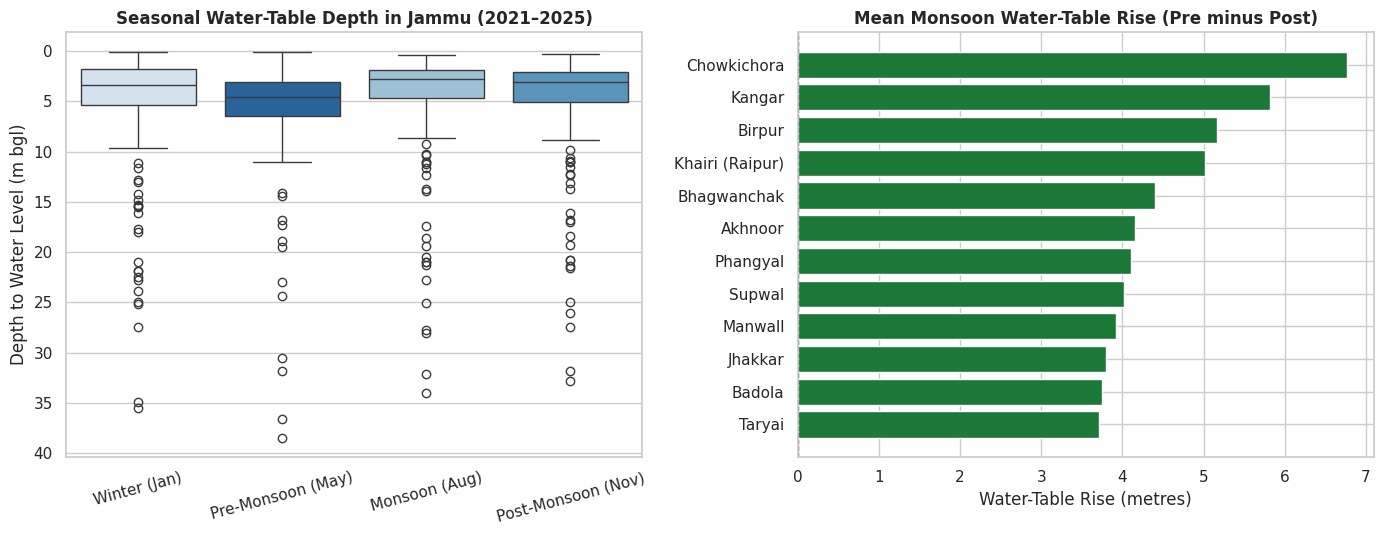

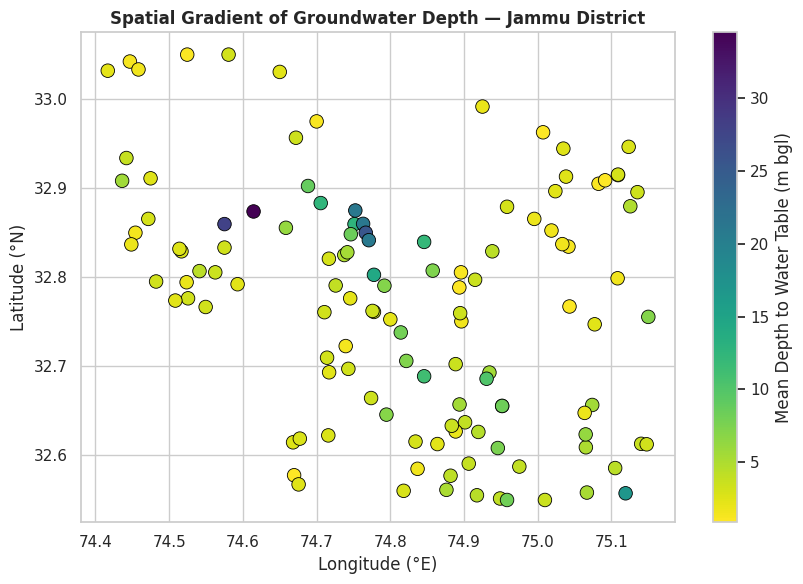


================ COPY THIS SUMMARY BACK TO ME ================
Jammu GWL stations: 122 | Readings: 777
Years covered (GWL): 2021 to 2023
Median water depth: 3.30 m bgl (Min: 0.06, Max: 38.46)
Median monsoon water-table rise: 1.46 m


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
!pip -q install folium

import matplotlib.pyplot as plt
import seaborn as sns
import folium
from google.colab import files

sns.set_theme(style="whitegrid", context="notebook")

# 1. Pre- vs Post-Monsoon Recharge Rise (Positive = water table rose after monsoon)
seasonal_piv = (
    gwl_jammu[gwl_jammu["season"].isin(["Pre-Monsoon (May)", "Post-Monsoon (Nov)"])]
    .pivot_table(index=["station", "year"], columns="season", values="water_level_mbgl", aggfunc="mean")
    .reset_index()
)

station_recharge = pd.DataFrame()
if {"Pre-Monsoon (May)", "Post-Monsoon (Nov)"}.issubset(seasonal_piv.columns):
    seasonal_piv["recharge_rise_m"] = seasonal_piv["Pre-Monsoon (May)"] - seasonal_piv["Post-Monsoon (Nov)"]
    station_recharge = (
        seasonal_piv.groupby("station", as_index=False)["recharge_rise_m"]
        .mean()
        .dropna()
        .sort_values("recharge_rise_m", ascending=False)
    )

# FIGURE 1: Seasonal Water Depth & Monsoon Recharge
season_order = ["Winter (Jan)", "Pre-Monsoon (May)", "Monsoon (Aug)", "Post-Monsoon (Nov)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.boxplot(
    data=gwl_jammu,
    x="season",
    y="water_level_mbgl",
    order=[s for s in season_order if s in gwl_jammu["season"].unique()],
    hue="season",
    legend=False,
    palette="Blues",
    ax=axes[0],
)
axes[0].invert_yaxis()
axes[0].set_title("Seasonal Water-Table Depth in Jammu (2021–2025)", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Depth to Water Level (m bgl)")
axes[0].tick_params(axis="x", rotation=15)

if not station_recharge.empty:
    top_r = station_recharge.head(12)
    colors = ["#1b7837" if v >= 0 else "#d73027" for v in top_r["recharge_rise_m"]]
    axes[1].barh(top_r["station"], top_r["recharge_rise_m"], color=colors)
    axes[1].axvline(0, color="black", linewidth=0.9, linestyle="--")
    axes[1].invert_yaxis()
    axes[1].set_title("Mean Monsoon Water-Table Rise (Pre minus Post)", fontweight="bold")
    axes[1].set_xlabel("Water-Table Rise (metres)")
    axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("outputs/figures/fig1_seasonal_water_level_jammu.png", dpi=300, bbox_inches="tight")
plt.show()

# FIGURE 2: Electrical Conductivity Quality Distribution
if "ec_us_cm" in gwq_jammu.columns and gwq_jammu["ec_us_cm"].notna().sum() > 5:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(gwq_jammu["ec_us_cm"].dropna(), bins=25, kde=True, color="#2b8cbe", ax=axes[0])
    axes[0].axvline(750, color="#1b7837", linestyle="--", label="Good (750 µS/cm)")
    axes[0].axvline(1500, color="#e6550d", linestyle="--", label="Permissible (1500 µS/cm)")
    axes[0].set_title("Jammu Groundwater EC Distribution", fontweight="bold")
    axes[0].set_xlabel("Electrical Conductivity (µS/cm)")
    axes[0].legend()

    yr_ec = gwq_jammu.groupby("year")["ec_us_cm"].median().dropna()
    axes[1].plot(yr_ec.index, yr_ec.values, marker="o", linewidth=2, color="#08519c")
    axes[1].axhline(750, color="#1b7837", linestyle=":", alpha=0.8)
    axes[1].set_title("Median Annual Groundwater EC in Jammu", fontweight="bold")
    axes[1].set_xlabel("Year")
    axes[1].set_ylabel("Median EC (µS/cm)")

    plt.tight_layout()
    plt.savefig("outputs/figures/fig2_ec_quality_jammu.png", dpi=300, bbox_inches="tight")
    plt.show()

# FIGURE 3 & INTERACTIVE MAP: Spatial Depth Gradient (Kandi vs Alluvial Plains)
stn_spatial = (
    gwl_jammu.groupby("station", as_index=False)
    .agg(lat=("lat", "median"), lon=("lon", "median"), mean_depth=("water_level_mbgl", "mean"))
    .dropna(subset=["lat", "lon"])
)

if not stn_spatial.empty:
    fig, ax = plt.subplots(figsize=(8.5, 6))
    sc = ax.scatter(
        stn_spatial["lon"], stn_spatial["lat"],
        c=stn_spatial["mean_depth"], cmap="viridis_r", s=95, edgecolor="black", linewidth=0.6
    )
    plt.colorbar(sc, ax=ax, label="Mean Depth to Water Table (m bgl)")
    ax.set_title("Spatial Gradient of Groundwater Depth — Jammu District", fontweight="bold")
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    plt.tight_layout()
    plt.savefig("outputs/figures/fig3_spatial_depth_jammu.png", dpi=300, bbox_inches="tight")
    plt.show()

    m = folium.Map(location=[stn_spatial["lat"].median(), stn_spatial["lon"].median()], zoom_start=10, tiles="CartoDB positron")
    for _, row in stn_spatial.iterrows():
        d = row["mean_depth"]
        color = "#2b83ba" if d < 5 else ("#abdda4" if d < 15 else ("#fdae61" if d < 30 else "#d7191c"))
        folium.CircleMarker(
            location=[row["lat"], row["lon"]],
            radius=7, color="#222222", weight=0.8, fill=True, fill_color=color, fill_opacity=0.85,
            popup=f"<b>{row['station']}</b><br>Mean Depth: {d:.2f} m bgl"
        ).add_to(m)
    m.save("outputs/jammu_groundwater_map.html")

# PRINT COPY-PASTEABLE SUMMARY FOR YOUR README
print("\n================ COPY THIS SUMMARY BACK TO ME ================")
print(f"Jammu GWL stations: {gwl_jammu['station'].nunique()} | Readings: {len(gwl_jammu)}")
print(f"Years covered (GWL): {int(gwl_jammu['year'].min())} to {int(gwl_jammu['year'].max())}")
print(f"Median water depth: {gwl_jammu['water_level_mbgl'].median():.2f} m bgl (Min: {gwl_jammu['water_level_mbgl'].min():.2f}, Max: {gwl_jammu['water_level_mbgl'].max():.2f})")
if not station_recharge.empty:
    print(f"Median monsoon water-table rise: {station_recharge['recharge_rise_m'].median():.2f} m")
if "ec_us_cm" in gwq_jammu.columns and gwq_jammu["ec_us_cm"].notna().any():
    ec_s = gwq_jammu["ec_us_cm"].dropna()
    print(f"Jammu GWQ EC readings: {len(ec_s)} | Median EC: {ec_s.median():.1f} µS/cm | Above 750: {(ec_s > 750).sum()} | Above 1500: {(ec_s > 1500).sum()}")
print("==============================================================")

# ZIP AND DOWNLOAD ALL OUTPUTS TO YOUR LAPTOP
!zip -rq jammu_project_a_results.zip outputs
files.download("jammu_project_a_results.zip")